# La atención de un modelo real

**Materiales desarrollados por Matías Barreto, 2026**

**Tecnicatura Superior en Ciencias de Datos e IA, IFTS N.º 24**
* **Nomenclatura oficial:** Procesamiento de Lenguaje Natural
* **Nombre de trabajo:** Laboratorio de PLN: Analítica, Textos y Cultura

---

| | |
|---|---|
| **Problema** | En 010 ajustaste BETO sin ver qué pasa adentro. Adentro hay 12 capas con 12 cabezas de atención cada una: 144 matrices por oración, y en 02 miraste una de juguete. |
| **Producto** | Una lectura medida de la atención de BETO sobre dos versos del *Martín Fierro*, con una decisión sobre qué se puede afirmar a partir de ella. |
| **Recursos** | BETO ya descargado en 010 (unos 450 MB), PyTorch y Transformers. En CPU, una oración tarda unos segundos. |

Una matriz de atención parece una explicación: muestra qué token mira a cuál. Pero en un modelo real hay 144 por oración, y ninguna trae una etiqueta que diga qué hace.

**¿Qué se puede leer de la atención de un modelo real, y qué sería una afirmación excesiva?**

> **Cómo se trabaja.** Primero explorás cada tema con el código ya escrito y las notas **Para mirar**. Al final hay un **microlaboratorio**: una tabla te dice qué líneas completar y con qué, y la celda siguiente comprueba si quedó bien.

In [1]:
import numpy as np
import torch
import transformers
from transformers import AutoModel, AutoTokenizer

import utils

print(f"numpy {np.__version__}")
print(f"torch {torch.__version__}")
print(f"transformers {transformers.__version__}")
print("Sin azar: el modelo ya esta entrenado y no se entrena aca.")

numpy 2.5.4
torch 2.14.1
transformers 4.57.6
Sin azar: el modelo ya esta entrenado y no se entrena aca.


## 1. Un modelo que ya conocés y dos versos

| | |
|---|---|
| **Modelo** | BETO, `dccuchile/bert-base-spanish-wwm-uncased`, el mismo de 010. Solo entiende minúsculas: el tokenizador convierte todo. |
| **Texto** | Dos versos de *El gaucho Martín Fierro* (1872), de José Hernández, en dominio público. Son el comienzo de la 4.ª estrofa de `martin_fierro_estrofas.csv`, en 010. |
| **Qué es esto** | Una inspección de **un** ejemplo. No evalúa el modelo ni prueba nada sobre el español. |

BETO se carga con cuatro ajustes que importan para este cuaderno.

| Ajuste | Qué hace | Si lo cambiás |
|---|---|---|
| `output_attentions=True` | Pide que el modelo devuelva, además de sus vectores, los pesos de atención de cada capa. | Sin él no hay nada que mirar. |
| `attn_implementation="eager"` | Usa el cálculo de atención escrito paso a paso, que sí expone los pesos. | La versión rápida no los devuelve. |
| `add_pooling_layer=False` | Omite una capa final que BETO trae para clasificar y acá no se usa. | No cambia la atención. |
| `modelo.eval()` | Apaga el dropout, un azar interno que solo se usa al entrenar. | Si lo omitís, la atención cambia en cada corrida. |

In [2]:
MODELO = "dccuchile/bert-base-spanish-wwm-uncased"
VERSOS = "Yo he visto muchos cantores, Con famas bien obtenidas,"

tokenizador = AutoTokenizer.from_pretrained(MODELO)
modelo = AutoModel.from_pretrained(
    MODELO,
    add_pooling_layer=False,
    output_attentions=True,
    attn_implementation="eager",
)
modelo.eval()

print(f"capas: {modelo.config.num_hidden_layers}")
print(f"cabezas por capa: {modelo.config.num_attention_heads}")

capas: 12
cabezas por capa: 12


15 tokens


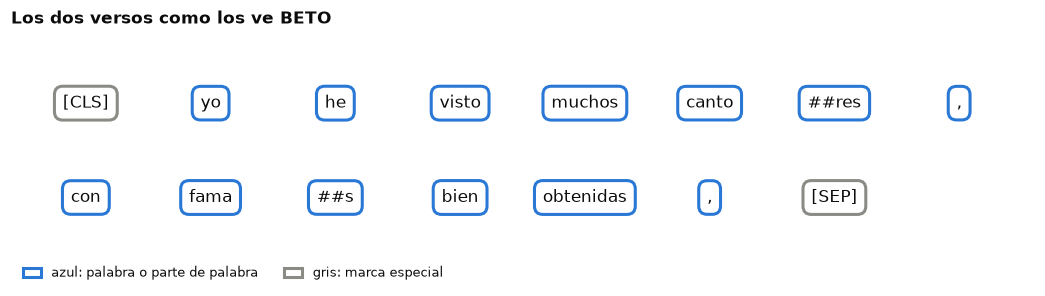

In [3]:
codificado = tokenizador(VERSOS, return_tensors="pt")
tokens = tokenizador.convert_ids_to_tokens(codificado["input_ids"][0])

clases = []
for token in tokens:
    if token in ("[CLS]", "[SEP]"):
        clases.append("marca")
    else:
        clases.append("palabra")

estilos = {
    "palabra": (utils.AZUL, "azul: palabra o parte de palabra"),
    "marca": (utils.GRIS, "gris: marca especial"),
}
print(f"{len(tokens)} tokens")
utils.dibujar_fichas(
    piezas=tokens,
    clases=clases,
    estilos=estilos,
    titulo="Los dos versos como los ve BETO",
    por_fila=8,
)

> **Para mirar.**
>
> - `cantores` se partió en `canto` y `##res`, y `famas` en `fama` y `##s`. El `##` marca una parte que continúa la palabra anterior.
> - `[CLS]` y `[SEP]` no son palabras: el tokenizador las agrega al principio y al final.
> - Todo quedó en minúsculas.

## 2. Ciento cuarenta y cuatro matrices para dos versos

El modelo devuelve los pesos de atención de cada capa. Se apilan en un solo arreglo con cuatro ejes: capa, cabeza, token que consulta y token considerado.

In [4]:
# no_grad evita guardar lo que solo hace falta para entrenar.
with torch.no_grad():
    salida = modelo(**codificado)

# attentions trae una matriz por capa; [:, 0] descarta el eje de lote.
atenciones = torch.stack(salida.attentions)[:, 0].numpy()
sumas_por_fila = atenciones.sum(axis=-1)

print(f"forma: {atenciones.shape}")
print(f"cada fila suma entre {sumas_por_fila.min():.3f} "
      f"y {sumas_por_fila.max():.3f}")

forma: (12, 12, 15, 15)
cada fila suma entre 1.000 y 1.000


peso promedio hacia los tokens de la derecha: 37%


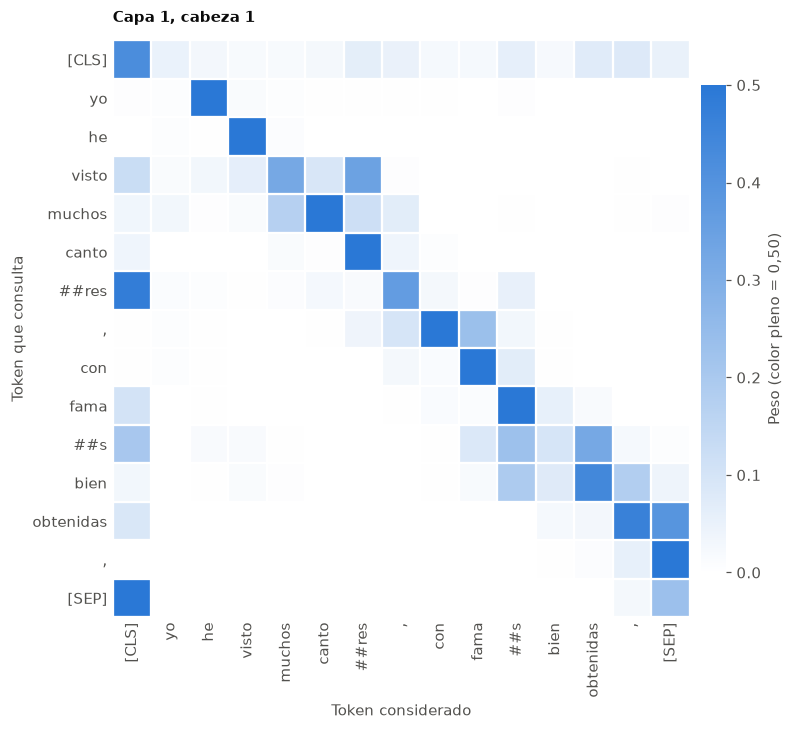

In [5]:
nombres_de_capas = []
nombres_de_cabezas = []
for numero in range(1, 13):
    nombres_de_capas.append(f"capa {numero}")
    nombres_de_cabezas.append(f"cabeza {numero}")

# En 02 el futuro valia cero; aca cuanto pesa lo que esta a la derecha.
peso_al_futuro = np.triu(atenciones, k=1).sum(axis=-1).mean()
print(f"peso promedio hacia los tokens de la derecha: {peso_al_futuro:.0%}")

utils.dibujar_mapa_de_calor(
    matriz=atenciones[0, 0],
    filas=tokens,
    columnas=tokens,
    titulo="Capa 1, cabeza 1",
    maximo=0.5,
)

> **Para mirar.**
>
> - Cada fila suma 1, como en 02. Pero acá hay peso a ambos lados de la diagonal: en promedio, más de un tercio de la atención va a tokens que están a la derecha. BETO lee la oración completa.
> - GPT-2 usa el mismo mecanismo con la máscara causal de 02. Esa máscara es una decisión de diseño, no una propiedad de la atención.
> - Esta es la primera cabeza, no una elegida por lo que muestra. Casi todo su peso cae justo a la derecha de la diagonal: la sección 4 mide ese tipo de patrón.

## 3. Dónde va la atención

Antes de mirar cabezas sueltas, una medida global, fijada de antemano: en cada capa, cuánto peso reciben en promedio las dos marcas `[CLS]` y `[SEP]`, que no son palabras.

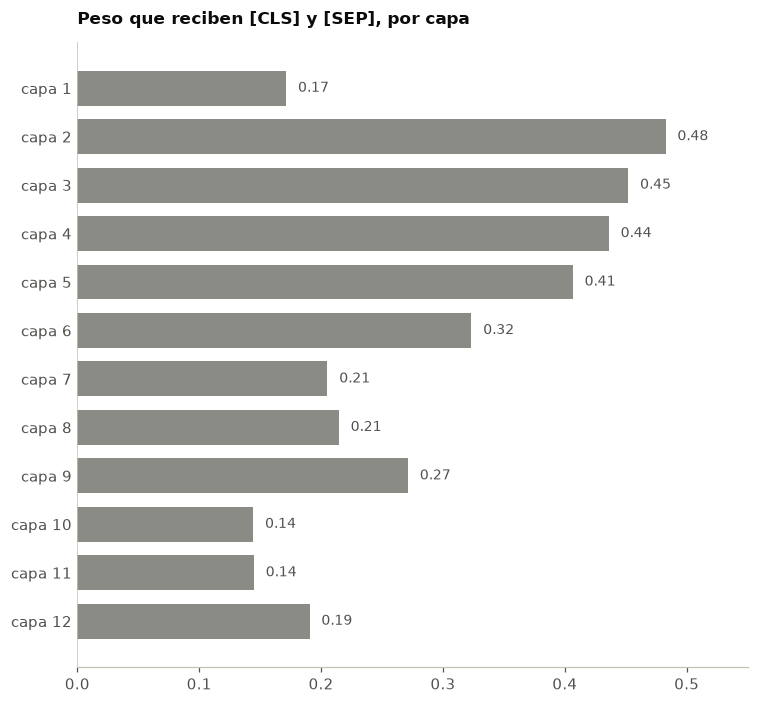

In [6]:
peso_a_marcas = []
for capa in range(12):
    hacia_cls = atenciones[capa, :, :, 0].mean()
    hacia_sep = atenciones[capa, :, :, -1].mean()
    peso_a_marcas.append(hacia_cls + hacia_sep)

utils.dibujar_barras(
    nombres=nombres_de_capas,
    valores=peso_a_marcas,
    titulo="Peso que reciben [CLS] y [SEP], por capa",
    color=utils.GRIS,
)

> **Para mirar.**
>
> - En las capas 2 a 5, entre el 41 % y el 48 % de la atención va a dos marcas que no son palabras.
> - Un peso alto no es información relevante: lo que recibe una marca no dice nada sobre el significado de los versos.

## 4. Cabezas que miran siempre al mismo lugar

Con 144 cabezas, mirar una por una no alcanza. Se fija un criterio antes de mirar: la fracción del peso que una cabeza dedica al token anterior y al siguiente. Si una cabeza hace siempre lo mismo, esa medida la va a mostrar.

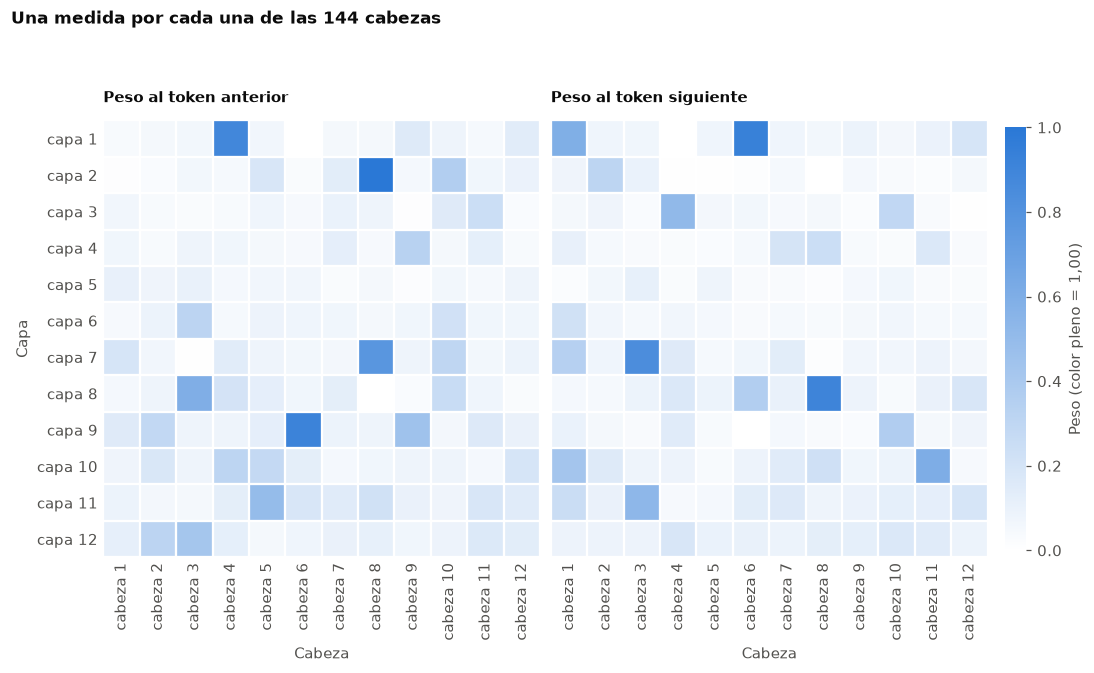

In [7]:
def fraccion_a_distancia(matriz: np.ndarray, distancia: int) -> float:
    """Mide cuanto peso va al token que esta a cierta distancia.

    Args:
        matriz: Pesos de una cabeza, una fila por token que consulta.
        distancia: Lugares de diferencia: -1 es el token anterior y 1,
            el siguiente.

    Returns:
        Promedio del peso que cada token da a ese vecino, entre los
        tokens que lo tienen.
    """
    pesos = []
    for consulta in range(len(matriz)):
        vecino = consulta + distancia
        if 0 <= vecino < len(matriz):
            pesos.append(matriz[consulta, vecino])
    return float(np.mean(pesos))


anterior = np.zeros((12, 12))
siguiente = np.zeros((12, 12))
for capa in range(12):
    for cabeza in range(12):
        matriz = atenciones[capa, cabeza]
        anterior[capa, cabeza] = fraccion_a_distancia(matriz, -1)
        siguiente[capa, cabeza] = fraccion_a_distancia(matriz, 1)

utils.dibujar_mapas_lado_a_lado(
    matrices={
        "Peso al token anterior": anterior,
        "Peso al token siguiente": siguiente,
    },
    filas=nombres_de_capas,
    columnas=nombres_de_cabezas,
    titulo="Una medida por cada una de las 144 cabezas",
    etiqueta_x="Cabeza",
    etiqueta_y="Capa",
)

anterior: capa 2, cabeza 8: 1.00
siguiente: capa 1, cabeza 6: 0.93
cabezas con mas de la mitad del peso en un vecino: 12 de 144


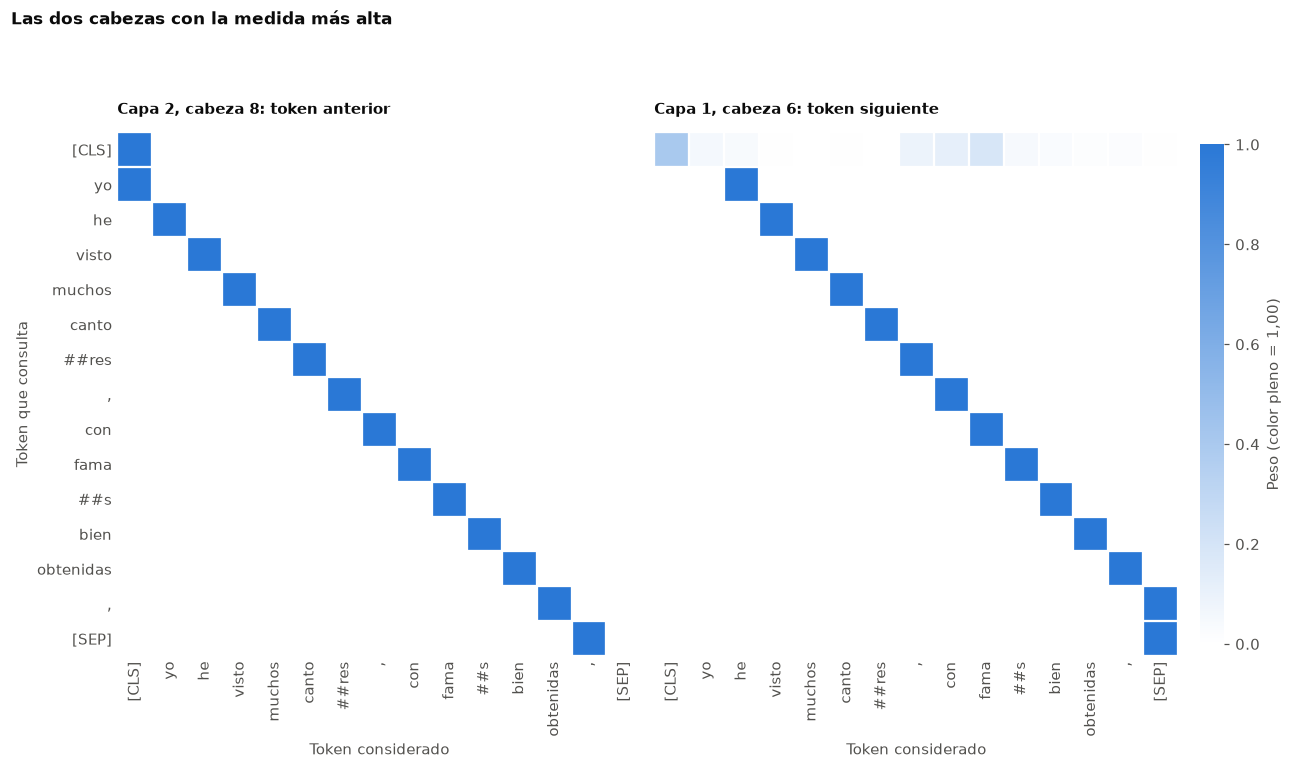

In [8]:
capa_a, cabeza_a = np.unravel_index(anterior.argmax(), anterior.shape)
capa_s, cabeza_s = np.unravel_index(siguiente.argmax(), siguiente.shape)
cabezas_con_regla = (anterior > 0.5) | (siguiente > 0.5)

print(f"anterior: capa {capa_a + 1}, cabeza {cabeza_a + 1}: "
      f"{anterior[capa_a, cabeza_a]:.2f}")
print(f"siguiente: capa {capa_s + 1}, cabeza {cabeza_s + 1}: "
      f"{siguiente[capa_s, cabeza_s]:.2f}")
print(f"cabezas con mas de la mitad del peso en un vecino: "
      f"{cabezas_con_regla.sum()} de 144")

utils.dibujar_mapas_lado_a_lado(
    matrices={
        f"Capa {capa_a + 1}, cabeza {cabeza_a + 1}: token anterior":
            atenciones[capa_a, cabeza_a],
        f"Capa {capa_s + 1}, cabeza {cabeza_s + 1}: token siguiente":
            atenciones[capa_s, cabeza_s],
    },
    filas=tokens,
    columnas=tokens,
    titulo="Las dos cabezas con la medida m\u00e1s alta",
    maximo=1.0,
)

> **Para mirar.**
>
> - Una cabeza manda prácticamente todo su peso al token anterior, y otra casi todo al siguiente: se ven como una diagonal pegada a la principal.
> - Son patrones de posición, no de significado. Se verifican con una regla (mirar al vecino) y no hace falta interpretar nada.
> - Solo 12 de las 144 cabezas ponen más de la mitad de su peso en alguno de los dos vecinos. Las otras 132 hacen otra cosa, y esta medida no dice qué.

Para repetir el procedimiento con otra oración, los pasos de la sección 2 se encapsulan en una función.

In [9]:
def atenciones_de(oracion: str) -> tuple[list[str], np.ndarray]:
    """Calcula los pesos de atencion de BETO para una oracion.

    Args:
        oracion: Texto en espanol.

    Returns:
        Los tokens y un arreglo con cuatro ejes: capa, cabeza, token que
        consulta y token considerado.
    """
    entrada = tokenizador(oracion, return_tensors="pt")
    with torch.no_grad():
        resultado = modelo(**entrada)
    apiladas = torch.stack(resultado.attentions)[:, 0].numpy()
    ids = entrada["input_ids"][0]
    return tokenizador.convert_ids_to_tokens(ids), apiladas


tokens_de_prueba, atenciones_de_prueba = atenciones_de(VERSOS)
print(np.allclose(atenciones_de_prueba, atenciones, atol=1e-5))

True


### Microlaboratorio 1 — ¿La cabeza «anterior» hace lo mismo con otros versos?

**Tarea.** Medí la cabeza que mira al token anterior (la de `capa_a` y `cabeza_a`) sobre una oración tuya.  
**Producto.** La fracción de peso que esa cabeza dedica al token anterior en tu oración.

| Línea | Qué tiene que quedar | Con qué |
|---|---|---|
| (1) | un verso o una oración en español, de al menos cuatro palabras | un texto entre comillas |
| (2) | los pesos de esa cabeza para tu oración | `atenciones_nuevas`, indexada con `capa_a` y `cabeza_a` |
| (3) | cuánto peso va al token anterior | `fraccion_a_distancia` con `matriz_nueva` y la distancia -1 |

> **Ayuda 1.** En la sección 2, `atenciones[0, 0]` es la matriz de la capa 1, cabeza 1: los dos primeros números eligen capa y cabeza.  
> **Ayuda 2.** La línea (3) repite la medida de la sección 4, con otra matriz.

In [10]:
oracion_nueva = ""  # COMPLETAR (1)
tokens_nuevos, atenciones_nuevas = atenciones_de(oracion_nueva)
matriz_nueva = np.eye(2)  # COMPLETAR (2)
fraccion_nueva = 0.0  # COMPLETAR (3)

print(f"tokens: {tokens_nuevos}")
print(f"peso al token anterior: {fraccion_nueva:.2f}")
utils.comprobar(
    len(oracion_nueva.split()) >= 4
    and np.allclose(matriz_nueva, atenciones_nuevas[capa_a, cabeza_a])
    and fraccion_nueva >= 0.8,
    "revisa (1) a (3): la matriz sale de la capa y la cabeza de arriba.",
)

tokens: ['[CLS]', '[SEP]']
peso al token anterior: 0.00
Todavia no. revisa (1) a (3): la matriz sale de la capa y la cabeza de arriba.


## 5. Lo que un mapa no muestra

Promediar las doce cabezas de una capa es una forma común de resumir. Qué queda de la cabeza que mediste recién cuando se la promedia con las otras once:

peso al token anterior, promedio de la capa: 0.17
peso al token anterior, solo esa cabeza: 1.00


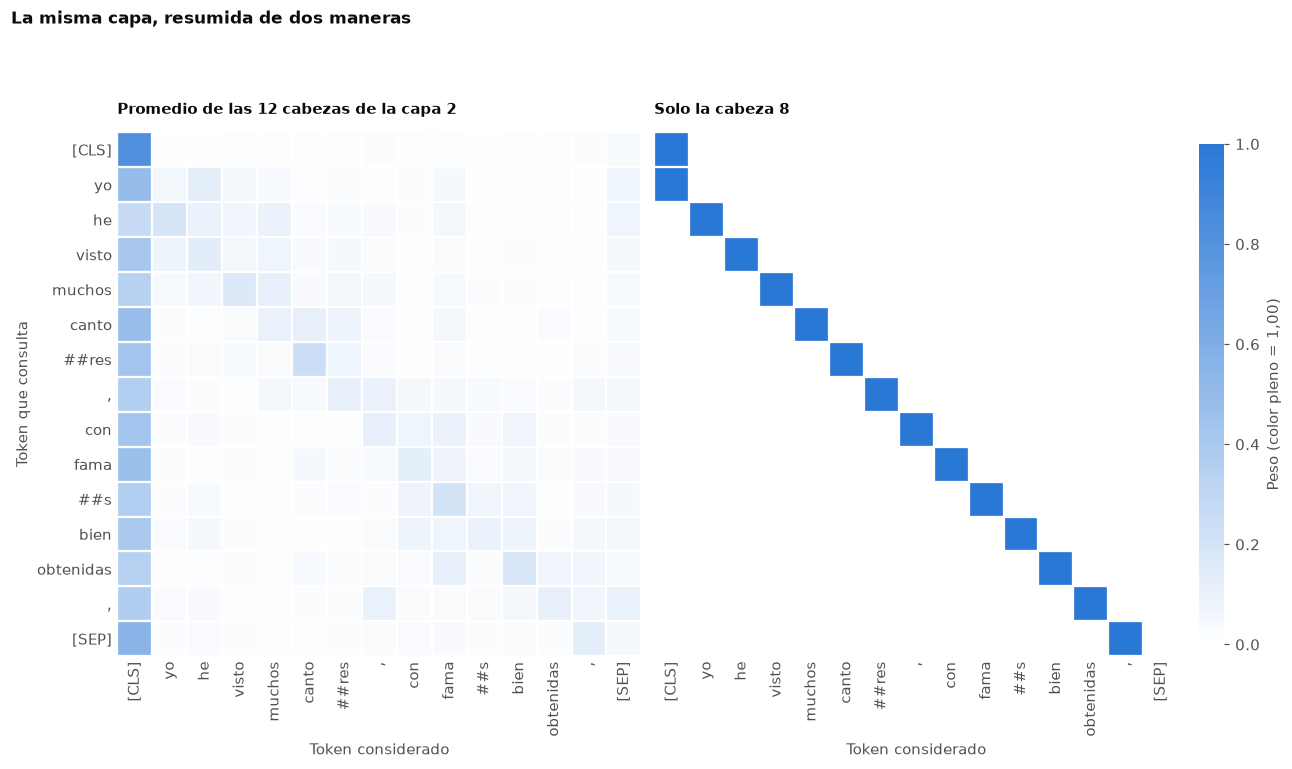

In [11]:
promedio_de_la_capa = atenciones[capa_a].mean(axis=0)
una_cabeza = atenciones[capa_a, cabeza_a]

print(f"peso al token anterior, promedio de la capa: "
      f"{fraccion_a_distancia(promedio_de_la_capa, -1):.2f}")
print(f"peso al token anterior, solo esa cabeza: "
      f"{fraccion_a_distancia(una_cabeza, -1):.2f}")

utils.dibujar_mapas_lado_a_lado(
    matrices={
        f"Promedio de las 12 cabezas de la capa {capa_a + 1}":
            promedio_de_la_capa,
        f"Solo la cabeza {cabeza_a + 1}": una_cabeza,
    },
    filas=tokens,
    columnas=tokens,
    titulo="La misma capa, resumida de dos maneras",
    maximo=1.0,
)

> **Para mirar.** El promedio diluye la regla que una sola cabeza cumple casi del todo. Y a la inversa: mirar una sola cabeza esconde lo que hacen las otras once de su capa. Ningún mapa resume por sí solo lo que hace el modelo.

## 6. Decidir qué se puede afirmar

| Afirmación | ¿Se sostiene con lo que se midió? | Por qué |
|---|---|---|
| «La cabeza de la capa 2 que mira al token anterior lo hace en estos versos.» | Sí | Se midió: es una regla sobre posiciones, con un número. |
| «BETO relaciona `cantores` con `famas`.» | No | Ninguna medición pone a prueba una relación entre esas palabras; un peso alto no es una relación. |
| «Cada cabeza cumple una función del lenguaje.» | No | Hay cabezas posicionales y capas donde casi la mitad del peso va a marcas sin significado; el resto no se examinó. |
| «La atención explica por qué BETO responde lo que responde.» | No | Haría falta intervenir (quitar o cambiar tokens y ver cómo cambia la salida), y acá no se hizo. |

**Decisión de uso.** La atención de un modelo real sirve para inspeccionar patrones que se pueden medir con una regla y para formular hipótesis. No alcanza como explicación de una decisión del modelo, ni con un mapa suelto ni con un promedio.

## Qué te llevás

- Un modelo real tiene 144 matrices de atención por oración, y cada una mira distinto. Una de juguete, como la de 02, muestra el mecanismo, no el modelo.
- Hay cabezas que cumplen una regla de posición medible, y capas que mandan casi la mitad del peso a marcas que no son palabras.
- Un mapa de atención es una observación, no una explicación: para afirmar algo hay que medirlo.

**Sigue:** en 012, GPT-2 usa este mismo mecanismo con la máscara causal para predecir el próximo token, y vas a ver cómo se arma el texto que lo alimenta.